# Figure 10: Cross-Frontal Transects

## Load Modules

In [1]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import matplotlib.ticker as mticker
from matplotlib import path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.patches import Polygon
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import matplotlib.transforms as mtransforms

import xarray as xr
from netCDF4 import Dataset
from xgcm import Grid
import cmaps
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob

import rioxarray

from dask.diagnostics import ProgressBar

from scipy.ndimage import gaussian_filter1d, label, binary_fill_holes, uniform_filter1d

from pyproj import Transformer

import seawater as sw
import gsw

import calendar

import pickle

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/sitecustomize.py:72: UserWarning: The seawater library is deprecated! Please use gsw instead.
  mod = _real_import(name, globals, locals, fromlist, level)


## Define Resuable Functions

In [2]:
def inpolygon(xq, yq, xv, yv):
    shape = xq.shape
    xq = xq.reshape(-1)
    yq = yq.reshape(-1)
    xv = xv.reshape(-1)
    yv = yv.reshape(-1)
    q = [(xq[i], yq[i]) for i in range(xq.shape[0])]
    p = path.Path([(xv[i], yv[i]) for i in range(xv.shape[0])])
    return p.contains_points(q).reshape(shape)

def createMasks(ds):
    ds['mask_zice'] = (ds.mask_rho.where(ds.zice<0)==1) # make a logic mask for ice
    ds['mask_openocean'] = ds.mask_rho*(ds.mask_zice==0)
    ds['mask_openoceanNaN'] = ds.mask_openocean.where(ds.mask_openocean)
    ds['mask_rhoNaN'] = ds.mask_rho.where(ds.mask_rho)
    ds['mask_ziceNaN'] = ds.mask_zice.where(ds.mask_zice)

    poly_shelf = np.array([
        [1.55e6,600000],
        [2.25e6,600000],
        [2.25e6,800000],
        [2.20e6,830000],
        [1.55e6,890000]])
    
    mask_roi = inpolygon(ds.x_rho.values, ds.y_rho.values,poly_shelf[:,0], poly_shelf[:,1])
    ds['mask_zice_roi'] = ds.mask_zice*mask_roi
    roi_label1 = 'amery'
    ds.mask_zice_roi.attrs['long_name']=roi_label1

# Find the coordinates of the four corners of one cell provided
def cell_polygon(j, i, x_psi, y_psi):
    """Corner coords of rho cell (j,i) from its 4 surrounding psi points."""
    # Convert psi (corner) points to a NumPy array
    xp, yp = np.asarray(x_psi), np.asarray(y_psi)
    return [(xp[j-1, i-1], yp[j-1, i-1]),   # SW
            (xp[j-1, i  ], yp[j-1, i  ]),   # SE
            (xp[j,   i  ], yp[j,   i  ]),   # NE
            (xp[j,   i-1], yp[j,   i-1])]   # NW

def block_polygon(j, i, x_psi, y_psi, r=1):
    """Outer boundary of a (2r+1)x(2r+1) block of rho cells centred on (j,i)."""
    xp, yp = np.asarray(x_psi), np.asarray(y_psi)
    return [(xp[j-1-r, i-1-r], yp[j-1-r, i-1-r]),   # SW
            (xp[j-1-r, i+r  ], yp[j-1-r, i+r  ]),   # SE
            (xp[j+r,   i+r  ], yp[j+r,   i+r  ]),   # NE
            (xp[j+r,   i-1-r], yp[j+r,   i-1-r])]   # NW
    
def nearest_cell(lon0, lat0, lon_rho, lat_rho):
    lon  = np.deg2rad(np.asarray(lon_rho)); lat  = np.deg2rad(np.asarray(lat_rho))
    lon0r, lat0r = np.deg2rad(lon0), np.deg2rad(lat0)
    dlon, dlat = lon - lon0r, lat - lat0r
    a = np.sin(dlat/2)**2 + np.cos(lat0r)*np.cos(lat)*np.sin(dlon/2)**2
    dist = 2*np.arcsin(np.sqrt(a))                      # great-circle distance
    j, i = np.unravel_index(np.nanargmin(dist), dist.shape)   # flat argmin -> (eta, xi)
    return int(j), int(i)

def style_map(ds, ax, boreholes_amisor, wct_colour=None):
    """Apply the common map overlays and extent to a panel."""
    # ax.contour(ds.x_rho, ds.y_rho, ds.h*ds.mask_rho, levels=(0,250,500,750,1000,2000,3000), colors='grey', linewidths=1)
    ax.contour(ds.x_rho, ds.y_rho, ds.zice*ds.mask_rho, levels=(-1,0), colors='red', linestyles='--', linewidths=0.75)

    wct = (ds.h + ds.zice) * ds.mask_rho # zice is negative, so this is h - |zice|
    if wct_colour is not None:
        cw = ax.contour(ds.x_rho, ds.y_rho, wct, levels=np.arange(0, 3000, 200), colors=wct_colour, linewidths=0.5, zorder=6)
    # ax.clabel(cw, inline=True, fontsize=6, fmt='%.0f')
        
    # Zoomed out
    # ax.set_xlim(1.68e6, 2.45e6)
    # ax.set_ylim(0.52e6, 1.0e6)

    # Eastern flank zoomed in 
    # ax.set_xlim(1.975e6, 2.45e6)
    # ax.set_ylim(0.52e6, 0.75e6)

    # Just AIS
    ax.set_xlim(1.975e6, 2.25e6)
    ax.set_ylim(0.58e6, 0.84e6)

    # Set an equal aspect ratio so that the map doesn't get stretched
    ax.set_aspect('equal', adjustable='box')
    
    ax.xaxis.set_major_formatter(ticks_x)
    ax.yaxis.set_major_formatter(ticks_y)
    for name, info in boreholes_amisor.items():
        lon, lat = info['lonlat']
        bx, by = ll_to_xy.transform(lon, lat)                     # true site -> metres
        ax.plot(bx, by, '.', color='black', ms=10, zorder=8,
                path_effects=[pe.withStroke(linewidth=2, foreground='white')])
        # ax.annotate(name, xy=(bx, by), xytext=(6, 0), textcoords='offset points', color='blue', va='center', zorder=6, bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.4))
        if name in ("AM01", "AM04", "AM05"):
            dx, dy, ha, va = 6, 0, "left", "center"
        elif name == "AM02":
            dx, dy, ha, va = -6, 0, "right", "center"
        elif name == "AM03":
            dx, dy, ha, va = 0, 6, "center", "bottom"
        elif name == "AM06":
            dx, dy, ha, va = 0, -6, "center", "top"
        ax.annotate(name, xy=(bx, by), xytext=(dx, dy), textcoords='offset points', color='black', ha=ha, va=va, zorder=8,
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])

def compute_psi(ds, ubar_rho, vbar_rho):
    # rotate grid-relative -> true north
    ang = ds.angle.values
    vbar_north = ubar_rho.values * np.sin(ang) + vbar_rho.values * np.cos(ang)
    # column thickness and northward transport per unit width
    H = (ds.h + ds.zice).values
    dx = 1.0 / ds.pm.values
    mask = ds.mask_rho.values
    V_transport = vbar_north * H * dx
    V_transport = np.nan_to_num(V_transport, nan=0.0)    # <-- replace ALL NaN with 0, wherever they came from
    # integrate transport in x -> psi (Sv), mask land
    psi = np.cumsum(V_transport, axis=1) / 1e6
    return np.where(mask == 1, psi, np.nan)

def build_transect(waypoints_front, x_rho, y_rho, mask_rho):
    # Define empty lists to take the coordinates of these waypoints in the model grid coordinates, eta/xi
    waypoints_eta, waypoints_xi = [], []
    
    # Iterate over each waypoint 
    for wx, wy in waypoints_front:
        # Calc squared distance between this waypoint to every cell
        d2 = (x_rho - wx)**2 + (y_rho - wy)**2
        # Set all non-ocean cells to infinity, so that we never snap to them (i.e. we're picking min distance, so we make the distance infinity)
        d2[~mask_rho] = np.inf
        # Extract the grid location of the closest cell to each waypoint
        min_d2_eta, min_d2_xi = np.unravel_index(np.argmin(d2), d2.shape)
        waypoints_eta.append(min_d2_eta)
        waypoints_xi.append(min_d2_xi)
    
    # Define lists to hold the eta and xi coordinates of cells along the line (starting with the first waypoint)
    eta_front, xi_front = [waypoints_eta[0]], [waypoints_xi[0]]
    # Iterate over each waypoint - walking the grid between consecutive points
    for k in range(len(waypoints_eta) - 1):
        # Extract the iterate waypoint
        e0, i0 = waypoints_eta[k], waypoints_xi[k]
        # Extract the consecutive waypoint
        e1, i1 = waypoints_eta[k + 1], waypoints_xi[k + 1]
    
        # Determine how many grid cells must be stepped over (whichever of eta or xi has the greatest distance)
        n = max(abs(e1 - e0), abs(i1 - i0))
    
        # Iterate over the number of steps required to move from one waypoint to its consecutive
        for step in range(1, n + 1):
            # Add grid cells that builds a straight line between consecutive waypoints
            eta_front.append(int(round(e0 + (e1 - e0) * step / n)))
            xi_front.append(int(round(i0 + (i1 - i0) * step / n)))
    
    # Convert the lists of cells along the line into a numpy array
    eta_front = np.array(eta_front)
    xi_front = np.array(xi_front)
    
    # Keep only cells that are not the same
    keep = np.concatenate([[True], (np.diff(eta_front) != 0) | (np.diff(xi_front) != 0)])
    eta_front, xi_front = eta_front[keep], xi_front[keep]
    
    # Extract the cell positions in metres EPSG: 3031
    x_front, y_front = x_rho[eta_front, xi_front], y_rho[eta_front, xi_front]
    
    # Calculate the total distance of the transect
    dist_km = np.concatenate([[0.0], np.cumsum(np.hypot(np.diff(x_front), np.diff(y_front)))]) / 1e3
    
    print(f"{len(eta_front)} cells, {dist_km[-1]:.0f} km along front")
    print(f"any land cells on the transect? {(~mask_rho[eta_front, xi_front]).any()}")

    return {"eta_front": eta_front, "xi_front": xi_front, "x_front": x_front, "y_front": y_front, "dist_km": dist_km}

def prepare_transect(transect, x_rho, y_rho, h, zice, cavity, smooth=5):
    eta_front, xi_front = transect['eta_front'], transect['xi_front']
    x_front, y_front = transect['x_front'], transect['y_front']
    
    ################## REMOVE LATER ########################
    mid = len(eta_front) // 2
    
    # u_rho / v_rho point along the model's xi / eta axes, NOT east / north. On this
    # grid those axes line up with x_rho / y_rho, so they serve as x and y
    # components directly. The print confirms it: stepping one cell along xi should
    # change x but barely change y, giving a tilt near zero.
    tilt = np.degrees(np.arctan2(
        y_rho[eta_front[mid], xi_front[mid] + 1] - y_rho[eta_front[mid], xi_front[mid]],
        x_rho[eta_front[mid], xi_front[mid] + 1] - x_rho[eta_front[mid], xi_front[mid]]))
    print(f"xi-axis tilt relative to +x: {tilt:.2f} deg")
    ################## REMOVE LATER ########################
    
    # Determine the tangent of the transect at each cell - determine the x-direction movement and y-direction movement of the transect at each cell
    # np.gradient uses the cell before and ahead of each cell along the transect
    dx_front, dy_front = np.gradient(x_front), np.gradient(y_front)
    
    # Determine the length of each tangent vector
    tl = np.hypot(dx_front, dy_front)
    
    # Divide by the length to make it a unit vector --> unit tangent vector
    # This points ALONG the transect, in the direction the waypoints were drawn, so the waypoint order sets the sign convention
    tx, ty = dx_front / tl, dy_front / tl
    
    # A diagonal run across the grid comes out as a staircase, so the tangent can zigzag. If the velocity panel looks noisy run this
    if smooth:
        tx = uniform_filter1d(tx, size=smooth)
        ty = uniform_filter1d(ty, size=smooth)
        t_len = np.hypot(tx, ty)
        tx, ty = tx / t_len, ty / t_len
    transect['tx'], transect['ty'] = tx, ty

    # Wrap the index arrays in DataArrays that share a dimension name (arbitrarily: "transect")
    eix = xr.DataArray(eta_front, dims="transect")
    xix = xr.DataArray(xi_front, dims="transect")

    # Determine the depth at every s-coordinate level for every transect cell
    transect['z'] = ds_CTRL.z_rho0.isel(eta_rho=eix, xi_rho=xix).values

    # Determine the bathymetry at every transect cell
    transect['h'] = h[eta_front, xi_front] 

    # Determine the ice draft at every transect cell (0 if open ocean)
    transect['zice'] = zice[eta_front, xi_front] 

    ################## REMOVE LATER ########################
    # Sanity check halfway along: the shallowest s-level should sit just below zice
    # and the deepest just above -h. If they disagree the section is misplaced in
    # the vertical and nothing else will be trustworthy.
    print(f"depth check at mid-transect: top {transect['z'][-1, mid]:.1f} m "
          f"(zice {transect['zice'][mid]:.1f}), bottom {transect['z'][0, mid]:.1f} m (-h {-transect['h'][mid]:.1f})")
    ################## REMOVE LATER ########################

## Load Datasets

In [3]:
# ---------- GRID ----------
grd = xr.open_dataset('/g/data/jk72/deg581/apom/frc/amery_v2km_v13_grd.nc')

# ---------- MODEL OUTPUT ----------
ds_CTRL = xr.open_dataset('/g/data/gv90/ad6790/amery-amisor/data/proc/ctrl_climatology.nc', chunks={})
print(ds_CTRL.nbytes/1e9,'G')

# ---------- NEUTRAL DENSITY CURVES ----------
# Load in the neutral density contours as determined by Blanckensee et al. (2024)
with open("/g/data/gv90/ad6790/amery-amisor/data/external/SiennaNeve-CDObs-203a48c/Notebooks/neu_dens_contours.pkl", "rb") as f: 
    nd_contours = pickle.load(f)
x_curve1 = nd_contours["x_curve1"]  # 28.27 contour
y_curve1 = nd_contours["y_curve1"]
x_curve2 = nd_contours["x_curve2"]  # 28.00 contour
y_curve2 = nd_contours["y_curve2"]

40.109673352 G


In [4]:
# ---------- LIMA ----------
lima_full = rioxarray.open_rasterio('/g/data/jk72/deg581/apom/ana/data/raw/lima/00000-20080319-092059124.tif')
lima = lima_full.where((lima_full.x>1.68e6)&(lima_full.x<2.5e6)&(lima_full.y>.4e6)&(lima_full.y<1e6),drop=True)

## Handle Loaded Datasets

In [5]:
# ---------- GRID ----------
grd['hc']=ds_CTRL.hc
grd['s_w']=ds_CTRL.s_w
grd['s_rho']=ds_CTRL.s_rho
grd['Cs_w']=ds_CTRL.Cs_w
grd['Cs_r']=ds_CTRL.Cs_r

createMasks(grd)

# ---------- MODEL OUTPUT ----------
with ProgressBar():
    ds_CTRL = ds_CTRL.load()

[########################################] | 100% Completed | 536.40 s


## Find AMISOR Borehole Locations

In [6]:
# Initialise a dictionary to hold information on the physical boreholes and moorings
# Borehole lon/lats are at deployment (most change across recording period by less than ~2 km, and maximum ~5 km) 
# Index 0 is coordinates (lon, lat)
# Index 1 is a list of mooring depths in dbar (calculated from average pressure at deployment)
boreholes_amisor = {
    'AM01': {'lonlat': (71.417083, -69.442033), 'avg_pressures': [441.1, 581.6, 743.4], 'ice_draft': 422, 'ocean_floor': 783},
    'AM02': {'lonlat': (72.639983, -69.713767), 'avg_pressures': [338.5, 562.7, 770.2], 'ice_draft': 324, 'ocean_floor': 790},
    'AM03': {'lonlat': (70.332167, -70.561167), 'avg_pressures': [653.6, 861.5, 1211.1], 'ice_draft': 648, 'ocean_floor': 1265},
    'AM04': {'lonlat': (70.290333, -69.8995), 'avg_pressures': [550.4, 693.0, 814.7], 'ice_draft': 539, 'ocean_floor': 938},
    'AM05': {'lonlat': (69.675, -70.231667), 'avg_pressures': [580.5, 738.8, 876.6], 'ice_draft': 554, 'ocean_floor': 909},
    'AM06': {'lonlat': (71.363817, -70.236083), 'avg_pressures': [551.4, 680.8, 790.3], 'ice_draft': 533, 'ocean_floor': 827}
}

# Create a resuable transformation for converting (lon,lat) -> (x,y)
ll_to_xy = Transformer.from_crs("EPSG:4326", "EPSG:3031", always_xy=True) 

## Setup Cross-Frontal Transects

In [7]:
# --------------- 1 - FIND ICE SHELF FRONT ---------------
# Extract grid values, bathymetry, and ice draft as plain numpy
x_rho = ds_CTRL.x_rho.values
y_rho = ds_CTRL.y_rho.values
lon_rho = ds_CTRL.lon_rho.values
lat_rho = ds_CTRL.lat_rho.values
h = ds_CTRL.h.values
zice = ds_CTRL.zice.values
mask_rho = ds_CTRL.mask_rho.values.astype(bool)
cavity = ds_CTRL.mask_zice_roi.values.astype(bool)

waypoints_surface_path = np.array([
    [2.250e6, 0.689e6],
    [2.140e6, 0.697e6]
])

transect_surface = build_transect(waypoints_surface_path, x_rho, y_rho, mask_rho)

prepare_transect(transect_surface, x_rho, y_rho, h, zice, cavity, smooth=5)

56 cells, 113 km along front
any land cells on the transect? False
xi-axis tilt relative to +x: 0.00 deg
depth check at mid-transect: top -209.6 m (zice -208.6), bottom -799.2 m (-h -802.8)


## Define Consistent Arguments for Plotting

In [62]:
# #----- IF USING PCOLORMESH -----
# shading_type="auto"
# # shading_type="gouraud"

# # OR use cm.thermal
# temp_kwargs = dict(cmap='cmo.thermal', vmin=-2.3, vmax=-1.75, shading=shading_type)
# # OR use cm.haline
# salt_kwargs = dict(cmap='viridis', vmin=34.5, vmax=34.8, shading=shading_type)

#----- IF USING CONTOURF -----
# OR use cm.thermal
temp_kwargs = dict(cmap='cmo.thermal', levels=np.arange(-2.3,-1.39,.1), extend='both')
# OR use cm.haline
salt_kwargs = dict(cmap='viridis', levels=np.arange(34.5,34.81,.02), extend='both')

# pot_density_contour_kwargs = dict(colors="white", linewidths=1, levels=[27.5, 27.6, 27.7, 27.8, 27.9])
pot_density_contour_kwargs = dict(colors="white", linewidths=1, levels=np.arange(20, 40, 0.05))
contour_label_kwargs = dict(inline=True, fmt="%.2f", fontsize=8)
outline_kwargs = dict(color="black", lw=1)
vel_kwargs = dict(cmap=cmocean.cm.balance, levels=np.arange(-11, 11, 1), extend='both')
velocity_contour_kwargs = dict(levels=np.arange(-10, 11, 2), colors="0.25", linewidths=0.5, linestyles="solid")
neutral_density_contour_kwargs = dict(colors="red", linewidths=1)

plt.rcParams.update({
    'font.size': 12,          # base size, everything else scales from it
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
})

## Surface Transect & Sea Ice Seasons

In [67]:
transect = transect_surface

# late_summer_period
s1 = slice(20,80)
# early_seaice_period
s2 = slice(80,130)
# seaice_period
s3 = slice(130,330)
# early_summer_period1
s4_1 = slice(330,366)
# early_summer_period2
s4_2 = slice(0,20)

# Wrap the index arrays in DataArrays that share a dimension name (arbitrarily: "transect")
eix = xr.DataArray(transect['eta_front'], dims="transect")
xix = xr.DataArray(transect['xi_front'], dims="transect")

sub_all = ds_CTRL.isel(eta_rho=eix, xi_rho=xix)
# Subset to the transect cells and the chosen time frame
sub_s1 = ds_CTRL.isel(eta_rho=eix, xi_rho=xix).sel(dayofyear=s1)
sub_s2 = ds_CTRL.isel(eta_rho=eix, xi_rho=xix).sel(dayofyear=s2)
sub_s3 = ds_CTRL.isel(eta_rho=eix, xi_rho=xix).sel(dayofyear=s3)
sub_s4 = xr.concat([sub_all.sel(dayofyear=s4_1), sub_all.sel(dayofyear=s4_2)], dim="dayofyear")

# Average variables over the selected timeframe
CT_s1 = sub_s1.temp_doy.mean("dayofyear").values
CT_s2 = sub_s2.temp_doy.mean("dayofyear").values
CT_s3 = sub_s3.temp_doy.mean("dayofyear").values
CT_s4 = sub_s4.temp_doy.mean("dayofyear").values
SA_s1 = sub_s1.salt_doy.mean("dayofyear").values
SA_s2 = sub_s2.salt_doy.mean("dayofyear").values
SA_s3 = sub_s3.salt_doy.mean("dayofyear").values
SA_s4 = sub_s4.salt_doy.mean("dayofyear").values
u_x_s1 = sub_s1.u_rho_doy.mean("dayofyear").values    # velocity along the xi axis
u_x_s2 = sub_s2.u_rho_doy.mean("dayofyear").values    # velocity along the xi axis
u_x_s3 = sub_s3.u_rho_doy.mean("dayofyear").values    # velocity along the xi axis
u_x_s4 = sub_s4.u_rho_doy.mean("dayofyear").values    # velocity along the xi axis
u_y_s1 = sub_s1.v_rho_doy.mean("dayofyear").values    # velocity along the eta axis
u_y_s2 = sub_s2.v_rho_doy.mean("dayofyear").values    # velocity along the eta axis
u_y_s3 = sub_s3.v_rho_doy.mean("dayofyear").values    # velocity along the eta axis
u_y_s4 = sub_s4.v_rho_doy.mean("dayofyear").values    # velocity along the eta axis

# ---------- OPTIONAL: PROJECT ONTO TANGENT (PARALLEL TO TRANSECT) ----------
# Project velocity onto the tangent (dot product at every cell)
v_parallel_s1 = u_x_s1 * transect['tx'][None, :] + u_y_s1 * transect['ty'][None, :]
v_parallel_s2 = u_x_s2 * transect['tx'][None, :] + u_y_s2 * transect['ty'][None, :]
v_parallel_s3 = u_x_s3 * transect['tx'][None, :] + u_y_s3 * transect['ty'][None, :]
v_parallel_s4 = u_x_s4 * transect['tx'][None, :] + u_y_s4 * transect['ty'][None, :]

# ---------- OPTIONAL: PROJECT ONTO NORMAL (PERPENDICULAR TO TANGENT) ----------
# Calculate the unit normal to the transect - the tangent rotated 90 degrees anticlockwise, so it points to the LEFT of the direction the waypoints were drawn (i.e. eastward in this case)
nx, ny = -transect['ty'], transect['tx']

# Project velocity onto the normal (dot product at every cell) - the component flowing ACROSS the transect
v_cross_s1 = u_x_s1 * nx[None, :] + u_y_s1 * ny[None, :]
v_cross_s2 = u_x_s2 * nx[None, :] + u_y_s2 * ny[None, :]
v_cross_s3 = u_x_s3 * nx[None, :] + u_y_s3 * ny[None, :]
v_cross_s4 = u_x_s4 * nx[None, :] + u_y_s4 * ny[None, :]

# Calculate sigma0 - potential density referenced to the surface, minus 1000 kg/m3
sigma0_s1 = gsw.sigma0(SA_s1, CT_s1)
sigma0_s2 = gsw.sigma0(SA_s2, CT_s2)
sigma0_s3 = gsw.sigma0(SA_s3, CT_s3)
sigma0_s4 = gsw.sigma0(SA_s4, CT_s4)

# >>> NEW Potential density referenced to 400 dbar (near the depth of the frontal zone), minus 1000 kg/m3
p_ref = 400  # >>> NEW reference pressure (dbar)
sigma400_s1 = gsw.rho(SA_s1, CT_s1, p_ref) - 1000  # >>> NEW
sigma400_s2 = gsw.rho(SA_s2, CT_s2, p_ref) - 1000  # >>> NEW
sigma400_s3 = gsw.rho(SA_s3, CT_s3, p_ref) - 1000  # >>> NEW
sigma400_s4 = gsw.rho(SA_s4, CT_s4, p_ref) - 1000  # >>> NEW

# Sort neutral density curves as salinity at a given temp
sort_order_2800 = np.argsort(y_curve2)
curve2800_temp = np.asarray(y_curve2)[sort_order_2800]
curve2800_salt = np.asarray(x_curve2)[sort_order_2800]
sort_order_2827 = np.argsort(y_curve1)
curve2827_temp = np.asarray(y_curve1)[sort_order_2827]
curve2827_salt = np.asarray(x_curve1)[sort_order_2827]

CT_all = [CT_s1, CT_s2, CT_s3, CT_s4]
SA_all = [SA_s1, SA_s2, SA_s3, SA_s4]

/jobfs/181795289.gadi-pbs/ipykernel_2612475/1488401666.py:23: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  sub_s4 = xr.concat([sub_all.sel(dayofyear=s4_1), sub_all.sel(dayofyear=s4_2)], dim="dayofyear")


### Plot Ice Shelf Path Cross-Sections

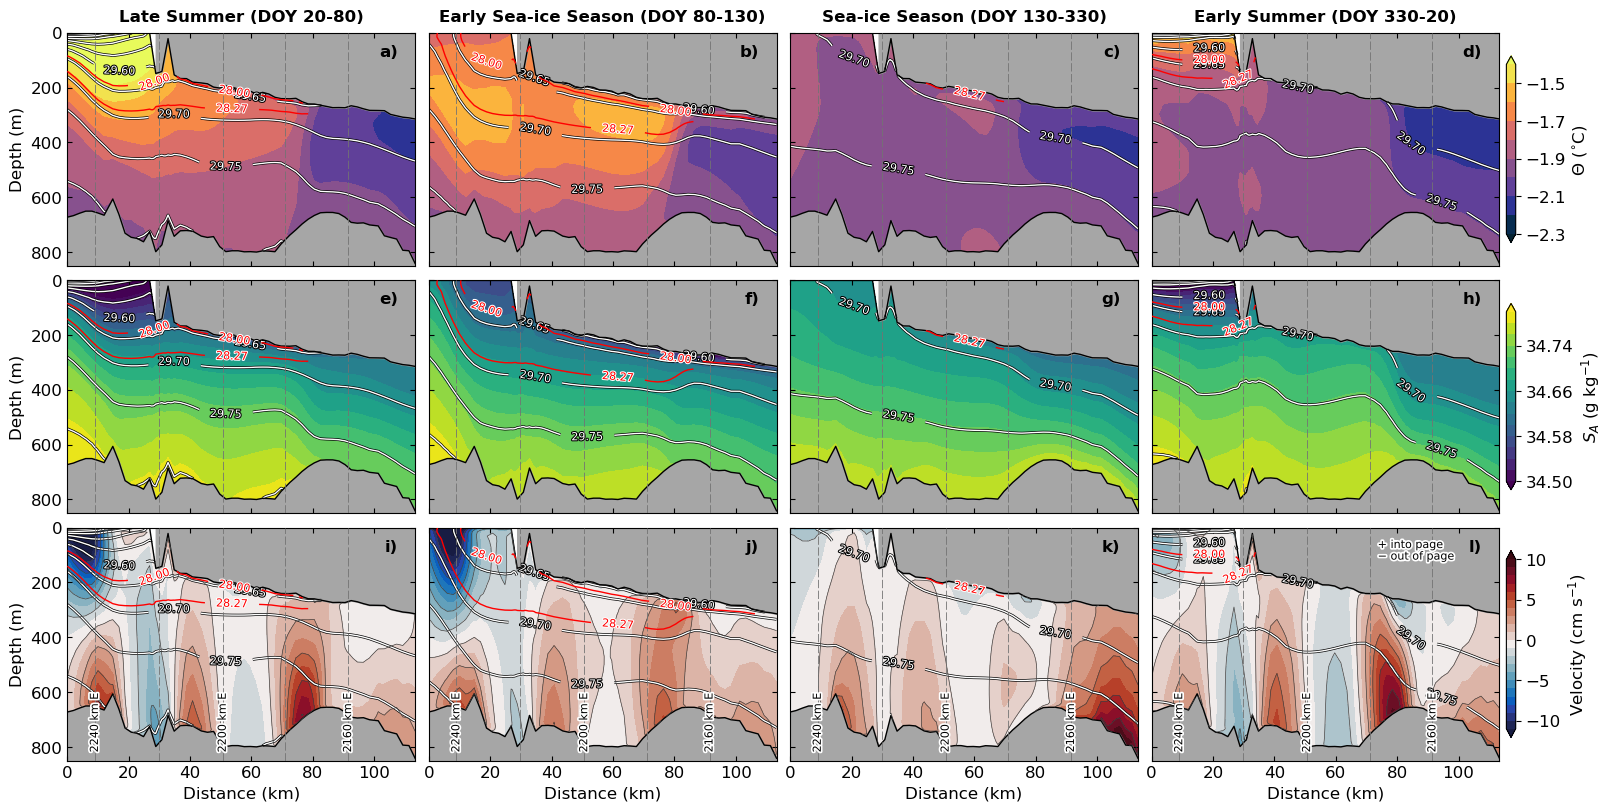

In [73]:
# pcolormesh needs x, y and the field all the same shape. dist_km holds one value per cell, so tile it down the 31 s-levels to match z_t and CT.
dist_2d = np.tile(transect['dist_km'], (transect['z'].shape[0], 1))

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16,8), sharex=True, sharey=True, layout='constrained')

# ----- Conservative Temperature -----
ct0=axes[0,0].contourf(dist_2d, transect['z'], CT_s1, **temp_kwargs)
ct1=axes[0,1].contourf(dist_2d, transect['z'], CT_s2, **temp_kwargs)
ct2=axes[0,2].contourf(dist_2d, transect['z'], CT_s3, **temp_kwargs)
ct3=axes[0,3].contourf(dist_2d, transect['z'], CT_s4, **temp_kwargs)

# ----- Absolute Salinity -----
sa0=axes[1,0].contourf(dist_2d, transect['z'], SA_s1, **salt_kwargs)
sa1=axes[1,1].contourf(dist_2d, transect['z'], SA_s2, **salt_kwargs)
sa2=axes[1,2].contourf(dist_2d, transect['z'], SA_s3, **salt_kwargs)
sa3=axes[1,3].contourf(dist_2d, transect['z'], SA_s4, **salt_kwargs)

# ----- Cross-Transect Velocity -----
v_cross0=axes[2,0].contourf(dist_2d, transect['z'], v_cross_s1*100, **vel_kwargs)
v_cross1=axes[2,1].contourf(dist_2d, transect['z'], v_cross_s2*100, **vel_kwargs)
v_cross2=axes[2,2].contourf(dist_2d, transect['z'], v_cross_s3*100, **vel_kwargs)
v_cross3=axes[2,3].contourf(dist_2d, transect['z'], v_cross_s4*100, **vel_kwargs)

sigma0_all = [sigma0_s1, sigma0_s2, sigma0_s3, sigma0_s4]
sigma400_all = [sigma400_s1, sigma400_s2, sigma400_s3, sigma400_s4]
v_parallel_all = [v_cross_s1, v_cross_s2, v_cross_s3, v_cross_s4]

# Since contourf fills only between data points and data points sit on cell centres, it can leave an annoying little white gap at the seabed and ice base
# So we define the seabed from the deepest cell centre, and vice versa for ice base
z_bot = transect['z'][0, :]      # deepest cell centre
z_top = transect['z'][-1, :]     # shallowest cell centre

# Eastings to mark, in EPSG:3031 metres
eastings = np.arange(2.16e6, 2.26e6, 20e3)

# Find where each easting crosses the transect, and how far along that is.
# np.interp needs increasing x, so flip if the transect runs east to west.
x_t, d_t = transect['x_front'], transect['dist_km']
if x_t[0] > x_t[-1]:
    x_t, d_t = x_t[::-1], d_t[::-1]

# Keep only eastings the transect actually spans
eastings = eastings[(eastings >= x_t.min()) & (eastings <= x_t.max())]
easting_dist = np.interp(eastings, x_t, d_t)

# Panel labels run left to right, then down
panel_labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l']

season_names = ['Late Summer (DOY 20-80)', 'Early Sea-ice Season (DOY 80-130)', 'Sea-ice Season (DOY 130-330)', 'Early Summer (DOY 330-20)']

axes[0,0].yaxis.set_major_locator(mticker.MultipleLocator(200))

for i in range(3):    
    axes[i,0].set_ylabel("Depth (m)")
    
    axes[i,0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{abs(v):.0f}"))
    
    for j in range(4):
        # Draw dotted lines delineating the eastings that the transects intercepts
        for xd in easting_dist:
            axes[i,j].axvline(xd, color="0.45", lw=0.6, ls=(0, (10, 3)), zorder=7) 
        # Draw labels on the eastings only in the bottom plots
        if i == 2:
            for xd, xn in zip(easting_dist[::2], eastings[::2]):
                t = axes[2,j].text(xd, -820, f"{xn/1e3:.0f} km E", rotation=90, ha="center", va="bottom", fontsize=8, zorder=10)
                t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="w")])
        
        # Plot contours for variables
        # if i == 0:
        #     c = axes[i,j].contour(dist_2d, transect['z'], [CT_s1,CT_s2,CT_s3,CT_s4][j], levels=np.arange(-2.3, -1.39, 0.1), colors="k", linewidths=0.6, linestyles="solid")
        #     axes[i,j].clabel(c, **contour_label_kwargs)
        # elif i == 1:
        #     c = axes[i,j].contour(dist_2d, transect['z'], [SA_s1,SA_s2,SA_s3,SA_s4][j], levels=np.arange(34.5, 34.81, 0.1), colors="k", linewidths=0.6)
        #     axes[i,j].clabel(c, **contour_label_kwargs)
        
        # Potential density contours (isopycnals)
        cs = axes[i,j].contour(dist_2d, transect['z'], sigma400_all[j], **pot_density_contour_kwargs)
        cs.set(path_effects=[pe.withStroke(linewidth=2, foreground="black")])
        label = axes[i,j].clabel(cs, levels=[lev for lev in cs.levels if 29.6 - 1e-6 <= lev <= 29.8 - 1e-6], **contour_label_kwargs)
        for text in label:
            text.set_path_effects([pe.withStroke(linewidth=1.5, foreground="black")])

        # Offset from each curve, but blanked (NaN) wherever the cell is colder than the curve's coldest point -
        offset_2800 = np.where(CT_all[j] >= curve2800_temp.min(), SA_all[j] - np.interp(CT_all[j], curve2800_temp, curve2800_salt), np.nan)
        offset_2827 = np.where(CT_all[j] >= curve2827_temp.min(), SA_all[j] - np.interp(CT_all[j], curve2827_temp, curve2827_salt), np.nan)

        # Draw the two neutral density surfaces - dashed for 28.00, solid for 28.27
        c2800 = axes[i,j].contour(dist_2d, transect['z'], offset_2800, levels=[0], zorder=8, **neutral_density_contour_kwargs)
        c2827 = axes[i,j].contour(dist_2d, transect['z'], offset_2827, levels=[0], zorder=8, **neutral_density_contour_kwargs)
        
        # Label each line with its value - fmt maps the contour level (0) to the text shown
        for c, text in [(c2800, '28.00'), (c2827, '28.27')]:
            labels = axes[i,j].clabel(c, fmt={0: text}, fontsize=8, inline=True)
            for lab in labels:
                lab.set_path_effects([pe.withStroke(linewidth=1.5, foreground='white')])
        
        # Seabed
        axes[i,j].plot(transect['dist_km'], z_bot, **outline_kwargs)
        axes[i,j].fill_between(transect['dist_km'], z_bot, -900, color="0.65")
        # Ice draft
        axes[i,j].plot(transect['dist_km'], z_top, **outline_kwargs)
        axes[i,j].fill_between(transect['dist_km'], z_top, 0, where=transect['zice'] < 0, color="0.65")
        axes[i,j].set_ylim(-850, 0)
        
        axes[i,j].tick_params(axis="both", direction="in", top=True, right=True)

        k = i * 4 + j
        axes[i,j].text(0.95, 0.95, f'{chr(97 + k)})', transform=axes[i,j].transAxes, ha='right', va='top', fontweight='bold', zorder=10)

for j in range(4):
    # Velocity contours
    cs = axes[2,j].contour(dist_2d, transect['z'], v_parallel_all[j]*100, **velocity_contour_kwargs)
    
    axes[2,j].set_xlabel(r"Distance (km)")

    axes[0, j].annotate(season_names[j], xy=(0.5, 1), xycoords='axes fraction', xytext=(0, 6), textcoords='offset points', ha='center', va='bottom', fontweight='bold')
        
t = axes[2,3].text(0.65, 0.9, "+ into page\n− out of page", transform=axes[2,3].transAxes, ha="left", va="center", fontsize=8, zorder=10)
t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="w")])

cbar_t = fig.colorbar(ct3, ax=axes[0,3], shrink=0.8, pad=0.02, extend='both')
cbar_t.set_label(r"$\Theta$ ($^{\circ}$C)")
cbar_t.set_ticks(cbar_t.get_ticks()[::2])
cbar_s = fig.colorbar(sa3, ax=axes[1,3], shrink=0.8, pad=0.02, extend='both')
cbar_s.set_label(r"$S_A$ (g kg$^{-1}$)")
cbar_s.set_ticks(cbar_s.get_ticks()[::2])
cbar_v = fig.colorbar(v_cross3, ax=axes[2,3], shrink=0.8, pad=0.02, extend='both')
cbar_v.set_label(r"Velocity (cm s$^{-1}$)")
cbar_v.set_ticks(np.arange(-10, 11, 5))

fig.canvas.draw()
fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ModelCrossFrontalTransect.jpg', format='jpg', dpi=300)
plt.show()

## Transect Location Map

<Figure size 640x480 with 0 Axes>

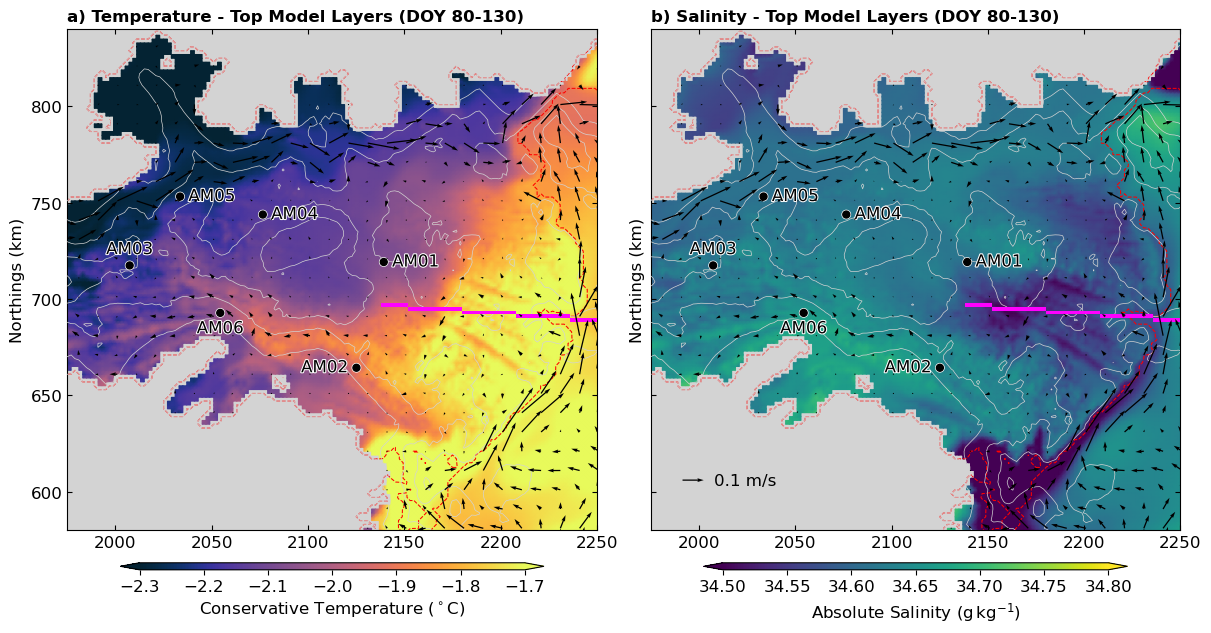

In [74]:
# OR use cm.thermal
temp_kwargs = dict(cmap='cmo.thermal', vmin=-2.3, vmax=-1.7, shading='gouraud', rasterized=True)
# OR use cm.haline
salt_kwargs = dict(cmap='viridis', vmin=34.5, vmax=34.8, shading='gouraud', rasterized=True)

plt.cla()
plt.clf()

# Quiver settings
res = 5
vel_scale = 2.5

# Colour for each transect - chosen to show up over both the temperature and salinity colourmaps
TRANSECT_COLOURS = {'Western Flank': 'white', 'Eastern Flank': 'magenta'}

# ---------- OCEAN CONDITIONS: TOP MODEL LAYERS ----------
# Vertical layers to average over
choose_depth = [-3, -2, -1]
# Compute the layer thicknesses for the chosen levels
dz_top = ds_CTRL.dz.isel(s_rho=choose_depth)
# Calculate the total thickness of all chosen levels
dz_sum = dz_top.sum('s_rho')
# Thickness-weighted mean over the top layers, then averaged over the season
temp_top = ((ds_CTRL.temp_doy.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum).sel(dayofyear=s2).mean('dayofyear')
salt_top = ((ds_CTRL.salt_doy.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum).sel(dayofyear=s2).mean('dayofyear')
u_top = ((ds_CTRL.u_rho_doy.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum).sel(dayofyear=s2).mean('dayofyear')
v_top = ((ds_CTRL.v_rho_doy.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum).sel(dayofyear=s2).mean('dayofyear')

# Mask of the cells the transect runs through
transect_mask = np.zeros(mask_rho.shape, dtype=bool)
transect_mask[transect['eta_front'], transect['xi_front']] = True

fig, ax = plt.subplots(1, 2, figsize=(12, 6.5), layout='constrained')

for i in range(2):
    ax[i].set_facecolor('lightgrey')

# ---------- TEMPERATURE (TOP) ----------
ax0=ax[0].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_top, **temp_kwargs)
ax[0].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], u_top.values[0::res,0::res], v_top.values[0::res,0::res],scale=vel_scale, zorder=9)

# ---------- SALINITY (TOP) ----------
ax1=ax[1].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_top, **salt_kwargs)
qu = ax[1].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], u_top.values[0::res,0::res], v_top.values[0::res,0::res],scale=vel_scale, zorder=9)

# Transect cells
ax[0].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, np.ma.masked_where(~transect_mask, transect_mask.astype(float)), cmap=mcolors.ListedColormap(['magenta']), shading='nearest', zorder=8)
ax[1].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, np.ma.masked_where(~transect_mask, transect_mask.astype(float)), cmap=mcolors.ListedColormap(['magenta']), shading='nearest', zorder=8)

scale_ticks = 1e3
ticks_x = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))
ticks_y = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))

for i in range(2):
    ax[i].set_title('')
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].tick_params(axis="both", direction="in", top=True, right=True)
    ax[i].set_ylabel('Northings (km)')
    style_map(ds_CTRL, ax[i], boreholes_amisor, wct_colour='lightgrey')
    
ax[0].set_title('a) Temperature - Top Model Layers (DOY 80-130)', loc='left', fontweight='bold')
ax[1].set_title('b) Salinity - Top Model Layers (DOY 80-130)', loc='left', fontweight='bold')

ax[0].set_ylabel('Northings (km)')
ax[1].tick_params(labelleft=False)

# Reference arrow for the currents
ax[1].quiverkey(qu, 0.1, 0.1, 0.1, '0.1 m/s', coordinates='axes', labelpos='E')

# Colourbars beneath each panel
cbar_t = fig.colorbar(ax0, ax=ax[0], location='bottom', shrink=0.8, pad=0.02, aspect=60, extend='both')
cbar_t.set_label(r'Conservative Temperature ($^\circ$C)')
cbar_s = fig.colorbar(ax1, ax=ax[1], location='bottom', shrink=0.8, pad=0.02, aspect=60, extend='both')
cbar_s.set_label(r'Absolute Salinity ($\mathrm{g\,kg^{-1}}$)')

fig.canvas.draw()
fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ModelCrossFrontalTransectMap.jpg', format='jpg', dpi=300)
plt.show()